# GBM path simulation

Exact simulation of Black-Scholes paths with continuous dividend yield:

$S_{t+\Delta t} = S_t \exp\left((r - q - \sigma^2/2)\Delta t + \sigma\sqrt{\Delta t}\,Z\right)$

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.rng import LCG
from src.paths import simulate_gbm

In [2]:
# Model parameters (theoretical asset, standard textbook values)
S0, r, q, sigma, T = 100.0, 0.05, 0.02, 0.20, 1.0
n_steps, n_paths = 50, 20_000

In [3]:
rng = LCG(seed=42)
paths = simulate_gbm(S0, r, q, sigma, T, n_steps, n_paths, rng)

print("Shape            :", paths.shape)
print("First columb = S0:", np.all(paths[:, 0] == S0))
print("All prices >     :", np.all(paths >0))
print(f"Mean of S_T     : {paths[:, -1].mean():.3f}")

Shape            : (20000, 51)
First columb = S0: True
All prices >     : True
Mean of S_T     : 102.993


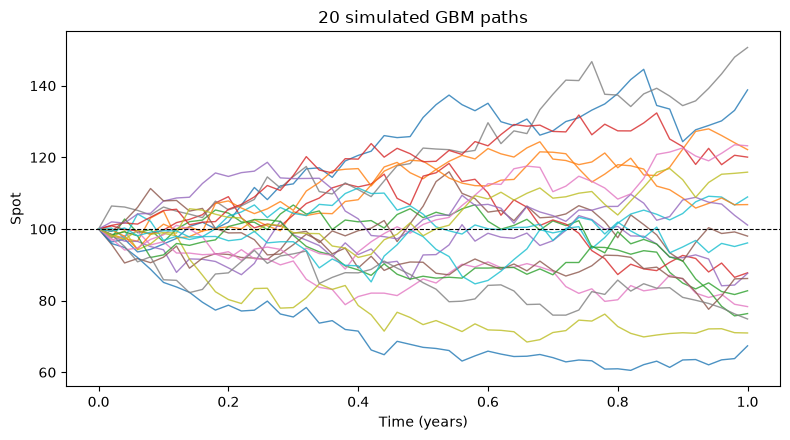

In [5]:
t = np.linspace(0, T, n_steps + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(t, paths[:20].T, lw=1, alpha=0.8)
plt.axhline(S0, color="black", linestyle="--", lw=0.8)
plt.title("20 simulated GBM paths")
plt.xlabel("Time (years)")
plt.ylabel("Spot")
plt.tight_layout()
plt.savefig("../figures/gbm_sample_paths.png", dpi=150)
plt.show()